In [57]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path

import sys
import json
import gc
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import ConfusionMatrixDisplay

In [58]:
import inspect
import src.trainer as trainer

print("Ruta del módulo:")
print(trainer.__file__)

source = inspect.getsource(
    trainer.train_one_epoch
)

print(
    "Normalización actualizada:",
    "loss_divisor" in source
)

print(
    "Registro de pasos omitidos:",
    "skipped_optimizer_steps" in source
)

Ruta del módulo:
C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\src\trainer.py
Normalización actualizada: True
Registro de pasos omitidos: True


In [59]:
PROJECT_DIR = Path(r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca")

DATASET_DIR = (
    PROJECT_DIR
    / "dataset"
    / "raw"
    / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"

REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR = PROJECT_DIR / "models"

LOGS_DIR = PROJECT_DIR / "logs"

for directory in [
    REPORTS_DIR,
    MODELS_DIR,
    LOGS_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(PROJECT_DIR)
    )

In [60]:
from src.utils import (
    set_seed,
    get_device
)

from src.preprocessing import (
    build_transforms
)

from src.data_generator import (
    create_fold_loaders
)

from src.model_factory import (
    create_model,
    configure_trainable_layers,
    count_parameters
)

from src.metrics import (
    calculate_class_weights,
    calculate_metrics,
    calculate_detailed_metrics
)

from src.trainer import (
    create_optimizer,
    create_scheduler,
    train_one_epoch,
    validate_one_epoch,
    fit
)

In [61]:
def load_json(filepath):

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as f:

        return json.load(f)


dataset_config = load_json(
    CONFIGS_DIR / "dataset_config.json"
)

training_config = load_json(
    CONFIGS_DIR / "training_config.json"
)

model_config = load_json(
    CONFIGS_DIR / "model_config.json"
)

SEED = dataset_config["seed"]

NUM_CLASSES = dataset_config[
    "dataset_statistics"
]["num_classes"]

CLASS_MAPPING = dataset_config[
    "class_mapping"
]

N_SPLITS = dataset_config[
    "cross_validation"
]["n_splits"]

DEVICE = get_device()

set_seed(SEED)

USE_AMP = DEVICE.type == "cuda"

print("Dispositivo:", DEVICE)

print("Mixed Precision:", USE_AMP)

print("Clases:", NUM_CLASSES)

print("Semilla:", SEED)

Dispositivo: cuda
Mixed Precision: True
Clases: 5
Semilla: 42


In [62]:
pipeline_config = {

    "optimizer": {
        "name": "AdamW",
        "weight_decay": 0.0001
    },

    "loss": {
        "name": "WeightedCrossEntropyLoss",
        "weight_method": "balanced",
        "reduction": "sum",
        "weights_source": "training_fold"
    },

    "feature_extraction": {
        "epochs": 3,
        "classifier_lr": 0.001
    },

    "partial_finetuning": {
        "epochs": 10,
        "classifier_lr": 0.0001,
        "backbone_lr": 0.00001
    },

    "scheduler": {
        "name": "ReduceLROnPlateau",
        "factor": 0.5,
        "patience": 1,
        "min_lr": 0.0000001
    },

    "early_stopping": {
        "patience": 3,
        "min_delta": 0.0
    },

    "selection_metric": "f1_macro",

    "mixed_precision": True,

    "effective_batch_size": 32,

    "seed": SEED

}

In [63]:
PIPELINE_CONFIG_PATH = (
    CONFIGS_DIR / "pipeline_config.json"
)

with open(
    PIPELINE_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        pipeline_config,
        f,
        indent=4
    )

print(
    "Configuración guardada:",
    PIPELINE_CONFIG_PATH
)

Configuración guardada: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\configs\pipeline_config.json


In [64]:
MODEL_NAME = "mobilenet_v3_large"

CURRENT_FOLD = 1

PILOT_FE_EPOCHS = 3

PILOT_FT_EPOCHS = 2

DROPOUT = model_config["default_dropout"]

BATCH_SIZE = training_config[
    "model_settings"
][MODEL_NAME]["batch_size"]

ACCUMULATION_STEPS = training_config[
    "model_settings"
][MODEL_NAME]["gradient_accumulation_steps"]

NUM_WORKERS = training_config[
    "training"
]["num_workers"]

RUN_NAME = (
    f"{MODEL_NAME}_fold_{CURRENT_FOLD}_v1"
)

CHECKPOINT_DIR = (
    MODELS_DIR / "pilot" / RUN_NAME
)

LOG_DIR = (
    LOGS_DIR / "pilot" / RUN_NAME
)

REPORT_DIR = (
    REPORTS_DIR / "pilot" / RUN_NAME
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Modelo:", MODEL_NAME)

print("Fold:", CURRENT_FOLD)

print("Batch físico:", BATCH_SIZE)

print(
    "Batch efectivo:",
    BATCH_SIZE * ACCUMULATION_STEPS
)

Modelo: mobilenet_v3_large
Fold: 1
Batch físico: 16
Batch efectivo: 32


In [65]:
df_splits = pd.read_csv(
    REPORTS_DIR / "dataset_splits.csv"
)

train_transform, eval_transform = (
    build_transforms(
        CONFIGS_DIR / "preprocessing_config.json"
    )
)

train_loader, val_loader = create_fold_loaders(
    df_splits=df_splits,
    dataset_dir=DATASET_DIR,
    class_mapping=CLASS_MAPPING,
    train_transform=train_transform,
    eval_transform=eval_transform,
    fold=CURRENT_FOLD,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    seed=SEED
)

print(
    "Imágenes de entrenamiento:",
    len(train_loader.dataset)
)

print(
    "Imágenes de validación:",
    len(val_loader.dataset)
)

print(
    "Batches de entrenamiento:",
    len(train_loader)
)

print(
    "Batches de validación:",
    len(val_loader)
)

Imágenes de entrenamiento: 12124
Imágenes de validación: 6063
Batches de entrenamiento: 758
Batches de validación: 379


In [66]:
df_train = train_loader.dataset.dataframe

df_val = val_loader.dataset.dataframe

df_test = df_splits[
    df_splits["split"] == "test"
]

train_hashes = set(df_train["sha256"])

val_hashes = set(df_val["sha256"])

test_hashes = set(df_test["sha256"])

assert train_hashes.isdisjoint(val_hashes)

assert train_hashes.isdisjoint(test_hashes)

assert val_hashes.isdisjoint(test_hashes)

assert (
    df_train["fold"] != CURRENT_FOLD
).all()

assert (
    df_val["fold"] == CURRENT_FOLD
).all()

assert (
    df_train["split"] == "development"
).all()

assert (
    df_val["split"] == "development"
).all()

print("Particiones verificadas correctamente.")

Particiones verificadas correctamente.


In [67]:
class_weights = calculate_class_weights(
    dataframe=df_train,
    class_mapping=CLASS_MAPPING
)

ordered_classes = sorted(
    CLASS_MAPPING,
    key=CLASS_MAPPING.get
)

df_class_weights = pd.DataFrame({

    "class": ordered_classes,

    "class_id": [
        CLASS_MAPPING[name]
        for name in ordered_classes
    ],

    "train_images": [
        (df_train["class"] == name).sum()
        for name in ordered_classes
    ],

    "weight": class_weights.numpy()

})

display(df_class_weights)

df_class_weights.to_csv(
    REPORT_DIR / "class_weights.csv",
    index=False,
    encoding="utf-8-sig"
)

,class,class_id,train_images,weight
0,bacterial_blight,0,616,3.936364
1,brown_streak_disease,1,1240,1.955484
2,green_mottle,2,1352,1.793491
3,healthy,3,1460,1.660822
4,mosaic_disease,4,7456,0.325215


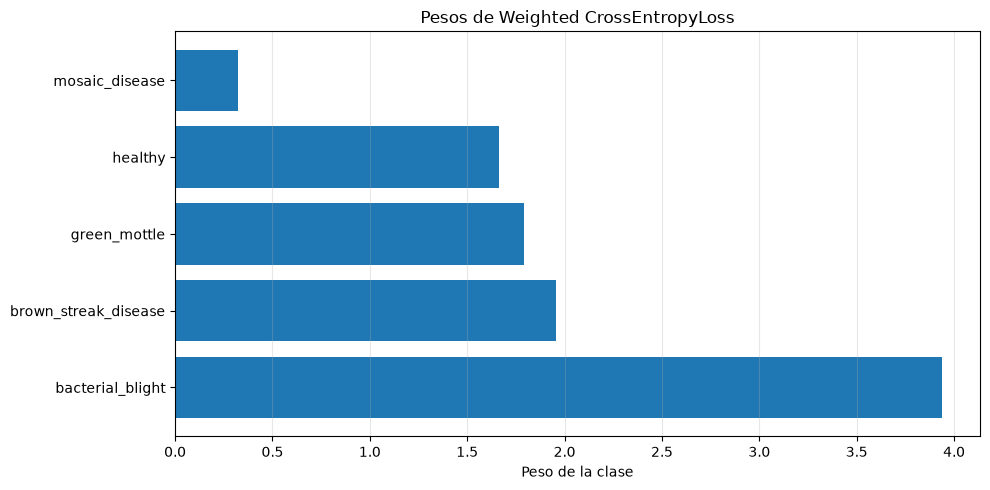

In [68]:
plt.figure(figsize=(10, 5))

plt.barh(
    df_class_weights["class"],
    df_class_weights["weight"]
)

plt.xlabel("Peso de la clase")

plt.title(
    "Pesos de Weighted CrossEntropyLoss"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "class_weights.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [69]:
set_seed(SEED)

model = create_model(
    model_name=MODEL_NAME,
    num_classes=NUM_CLASSES,
    pretrained=True,
    dropout=DROPOUT,
    mode="feature_extraction",
    device=DEVICE
)

display(
    count_parameters(model)
)

{'total_parameters': 4208437,
 'trainable_parameters': 1236485,
 'frozen_parameters': 2971952,
 'trainable_percentage': 29.381098018100303}

In [70]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE),
    reduction="sum"
)

print(criterion)

print(
    "Pesos:",
    criterion.weight
)

CrossEntropyLoss()
Pesos: tensor([3.9364, 1.9555, 1.7935, 1.6608, 0.3252], device='cuda:0')


In [71]:
optimizer = create_optimizer(
    model=model,
    model_name=MODEL_NAME,
    classifier_lr=pipeline_config[
        "feature_extraction"
    ]["classifier_lr"],
    weight_decay=pipeline_config[
        "optimizer"
    ]["weight_decay"]
)

scheduler = create_scheduler(
    optimizer=optimizer,
    factor=pipeline_config["scheduler"]["factor"],
    patience=pipeline_config["scheduler"]["patience"],
    min_lr=pipeline_config["scheduler"]["min_lr"]
)

for group in optimizer.param_groups:

    print(
        "Grupo:", group["name"],
        "| LR:", group["lr"]
    )

Grupo: classifier | LR: 0.001


In [73]:
from torch.utils.data import Subset

from src.data_generator import create_dataloader


small_train_dataset = Subset(
    train_loader.dataset,
    range(
        min(70, len(train_loader.dataset))
    )
)

small_val_dataset = Subset(
    val_loader.dataset,
    range(
        min(64, len(val_loader.dataset))
    )
)

small_train_loader = create_dataloader(
    dataset=small_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    seed=SEED
)

small_val_loader = create_dataloader(
    dataset=small_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    seed=SEED
)

print(
    "Imágenes de prueba:",
    len(small_train_dataset)
)

Imágenes de prueba: 70


In [74]:
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

smoke_train_metrics = train_one_epoch(
    model=model,
    model_name=MODEL_NAME,
    dataloader=small_train_loader,
    optimizer=optimizer,
    criterion=criterion,
    scaler=scaler,
    device=DEVICE,
    num_classes=NUM_CLASSES,
    accumulation_steps=ACCUMULATION_STEPS,
    use_amp=USE_AMP
)

smoke_val_metrics = validate_one_epoch(
    model=model,
    dataloader=small_val_loader,
    criterion=criterion,
    device=DEVICE,
    num_classes=NUM_CLASSES,
    use_amp=USE_AMP
)

display(
    pd.DataFrame([
        smoke_train_metrics,
        smoke_val_metrics
    ], index=["train", "validation"])
)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples,optimizer_steps
train,0.185714,0.185769,0.195338,0.124866,0.176218,0.195338,1.598558,1.879954,70,1.0
validation,0.500000,0.174359,0.236364,0.198431,0.402206,0.236364,1.681502,0.559266,64,NaN


In [75]:
expected_steps = math.ceil(
    len(small_train_loader)
    / ACCUMULATION_STEPS
)

assert np.isfinite(
    smoke_train_metrics["loss"]
)

assert np.isfinite(
    smoke_val_metrics["loss"]
)

assert smoke_train_metrics["num_samples"] == len(
    small_train_dataset
)

assert smoke_train_metrics["optimizer_steps"] > 0

actual_steps = smoke_train_metrics[
    "optimizer_steps"
]

skipped_steps = expected_steps - actual_steps

print("Actualizaciones esperadas:", expected_steps)

print("Actualizaciones realizadas:", actual_steps)

print("Actualizaciones omitidas:", skipped_steps)

if actual_steps == expected_steps:

    print("Pipeline verificado correctamente.")

else:

    print(
        "ADVERTENCIA: existen actualizaciones "
        "omitidas que requieren revisión."
    )

Actualizaciones esperadas: 3
Actualizaciones realizadas: 1
Actualizaciones omitidas: 2
ADVERTENCIA: existen actualizaciones omitidas que requieren revisión.


In [76]:
def test_precision_mode(
    use_amp,
    init_scale=1024.0
):

    set_seed(SEED)

    test_model = create_model(
        model_name=MODEL_NAME,
        num_classes=NUM_CLASSES,
        pretrained=True,
        dropout=DROPOUT,
        mode="feature_extraction",
        device=DEVICE
    )

    test_optimizer = create_optimizer(
        model=test_model,
        model_name=MODEL_NAME,
        classifier_lr=0.001,
        weight_decay=0.0001
    )

    test_scaler = torch.amp.GradScaler(
        "cuda",
        init_scale=init_scale,
        enabled=use_amp
    )

    test_loader = create_dataloader(
        dataset=small_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        seed=SEED
    )

    metrics = train_one_epoch(
        model=test_model,
        model_name=MODEL_NAME,
        dataloader=test_loader,
        optimizer=test_optimizer,
        criterion=criterion,
        scaler=test_scaler,
        device=DEVICE,
        num_classes=NUM_CLASSES,
        accumulation_steps=ACCUMULATION_STEPS,
        use_amp=use_amp
    )

    result = {
        "precision": "AMP FP16" if use_amp else "FP32",
        "initial_scale": init_scale if use_amp else None,
        "final_scale": test_scaler.get_scale(),
        "expected_steps": math.ceil(
            len(test_loader) / ACCUMULATION_STEPS
        ),
        "optimizer_steps": metrics["optimizer_steps"],
        "loss": metrics["loss"],
        "seconds": metrics["seconds"]
    }

    del test_model
    del test_optimizer
    del test_scaler
    del test_loader

    gc.collect()

    if DEVICE.type == "cuda":

        torch.cuda.empty_cache()

    return result

In [77]:
precision_results = []

configurations = [
    (False, 1.0),
    (True, 1024.0),
    (True, 128.0),
    (True, 32.0)
]

for use_amp, init_scale in configurations:

    print("\n" + "=" * 60)

    print("AMP:", use_amp)
    print("Initial scale:", init_scale)

    result = test_precision_mode(
        use_amp=use_amp,
        init_scale=init_scale
    )

    precision_results.append(result)

df_precision_test = pd.DataFrame(
    precision_results
)

display(df_precision_test)


AMP: False
Initial scale: 1.0

AMP: True
Initial scale: 1024.0

AMP: True
Initial scale: 128.0

AMP: True
Initial scale: 32.0


,precision,initial_scale,final_scale,expected_steps,optimizer_steps,loss,seconds
0,FP32,NaN,1.0,3,3,1.625389,1.466265
1,AMP FP16,1024.0,1024.0,3,3,1.624980,0.947910
2,AMP FP16,128.0,128.0,3,3,1.624980,1.067640
3,AMP FP16,32.0,32.0,3,3,1.624980,1.094258


In [78]:
# Verificación funcional del pipeline

smoke_result = test_precision_mode(
    use_amp=DEVICE.type == "cuda",
    init_scale=1024.0
)

expected_steps = smoke_result["expected_steps"]
actual_steps = smoke_result["optimizer_steps"]

skipped_steps = expected_steps - actual_steps

print("Precisión:", smoke_result["precision"])
print("Escala final:", smoke_result["final_scale"])
print("Actualizaciones esperadas:", expected_steps)
print("Actualizaciones realizadas:", actual_steps)
print("Actualizaciones omitidas:", skipped_steps)
print("Loss:", smoke_result["loss"])

assert np.isfinite(smoke_result["loss"]), (
    "La pérdida no es finita."
)

assert actual_steps == expected_steps, (
    "No se realizaron todas las actualizaciones."
)

print("\nPipeline verificado correctamente.")

Precisión: AMP FP16
Escala final: 1024.0
Actualizaciones esperadas: 3
Actualizaciones realizadas: 3
Actualizaciones omitidas: 0
Loss: 1.6249797905836343

Pipeline verificado correctamente.


In [19]:
del model
del optimizer
del scheduler
del scaler

gc.collect()

if DEVICE.type == "cuda":

    torch.cuda.empty_cache()

set_seed(SEED)

model = create_model(
    model_name=MODEL_NAME,
    num_classes=NUM_CLASSES,
    pretrained=True,
    dropout=DROPOUT,
    mode="feature_extraction",
    device=DEVICE
)

optimizer = create_optimizer(
    model=model,
    model_name=MODEL_NAME,
    classifier_lr=0.001,
    weight_decay=0.0001
)

scheduler = create_scheduler(
    optimizer=optimizer,
    factor=0.5,
    patience=1
)

print("Modelo reinicializado.")

Modelo reinicializado.


In [20]:
experiment_metadata = {

    "experiment": "pipeline_pilot",

    "architecture": MODEL_NAME,

    "fold": CURRENT_FOLD,

    "seed": SEED,

    "class_mapping": CLASS_MAPPING,

    "batch_size": BATCH_SIZE,

    "dropout": DROPOUT,

    "pretrained_weights": model_config[
        "architectures"
    ][MODEL_NAME]["weights"],

    "class_weights": class_weights.tolist(),

    "train_images": len(
        train_loader.dataset
    ),

    "validation_images": len(
        val_loader.dataset
    )

}

In [21]:
history_fe, summary_fe = fit(

    model=model,

    model_name=MODEL_NAME,

    train_loader=train_loader,

    val_loader=val_loader,

    optimizer=optimizer,

    criterion=criterion,

    device=DEVICE,

    num_classes=NUM_CLASSES,

    epochs=PILOT_FE_EPOCHS,

    checkpoint_dir=(
        CHECKPOINT_DIR / "feature_extraction"
    ),

    log_dir=(
        LOG_DIR / "feature_extraction"
    ),

    report_dir=(
        REPORT_DIR / "feature_extraction"
    ),

    accumulation_steps=ACCUMULATION_STEPS,

    use_amp=USE_AMP,

    scheduler=scheduler,

    patience=3,

    metadata=experiment_metadata

)

Epoch 01/03 | Train Loss: 1.0955 | Val Loss: 1.0875 | Train F1: 0.5122 | Val F1: 0.5394 | Tiempo: 4.20 min
Nuevo mejor checkpoint.
Epoch 02/03 | Train Loss: 0.9450 | Val Loss: 1.0922 | Train F1: 0.5793 | Val F1: 0.4948 | Tiempo: 3.95 min
Epoch 03/03 | Train Loss: 0.8911 | Val Loss: 1.0400 | Train F1: 0.6023 | Val F1: 0.5724 | Tiempo: 3.98 min
Nuevo mejor checkpoint.


In [22]:
display(history_fe)

display(summary_fe)

print(
    "Mejor época:",
    summary_fe["best_epoch"]
)

print(
    "Mejor F1 Macro:",
    summary_fe["best_f1_macro"]
)

print(
    "Tiempo total (min):",
    summary_fe["total_seconds"] / 60
)

,epoch,train_accuracy,train_precision_macro,train_recall_macro,train_f1_macro,train_f1_weighted,train_balanced_accuracy,train_loss,train_seconds,train_num_samples,...,val_recall_macro,val_f1_macro,val_f1_weighted,val_balanced_accuracy,val_loss,val_seconds,val_num_samples,lr_classifier,epoch_seconds,is_best
0,1,0.632712,0.488542,0.566441,0.512199,0.657896,0.566441,1.095483,176.280709,12124,...,0.565700,0.539406,0.696518,0.565700,1.087523,75.983646,6063,0.001,252.267497,True
1,2,0.694985,0.549513,0.635440,0.579272,0.713854,0.635440,0.944999,173.615596,12124,...,0.594827,0.494790,0.639517,0.594827,1.092209,63.439851,6063,0.001,237.057735,False
2,3,0.709832,0.570700,0.661406,0.602349,0.727431,0.661406,0.891122,175.586722,12124,...,0.614729,0.572400,0.723120,0.614729,1.039953,63.136918,6063,0.001,238.726105,True


{'architecture': 'mobilenet_v3_large',
 'best_epoch': 3,
 'best_f1_macro': 0.5724000496913045,
 'epochs_completed': 3,
 'total_seconds': 728.0513368000102,
 'early_stopping': False,
 'metadata': {'experiment': 'pipeline_pilot',
  'architecture': 'mobilenet_v3_large',
  'fold': 1,
  'seed': 42,
  'class_mapping': {'bacterial_blight': 0,
   'brown_streak_disease': 1,
   'green_mottle': 2,
   'healthy': 3,
   'mosaic_disease': 4},
  'batch_size': 16,
  'dropout': 0.2,
  'pretrained_weights': 'MobileNet_V3_Large_Weights.IMAGENET1K_V2',
  'class_weights': [3.936363697052002,
   1.9554839134216309,
   1.7934911251068115,
   1.6608219146728516,
   0.32521459460258484],
  'train_images': 12124,
  'validation_images': 6063,
  'training_mode': 'feature_extraction',
  'num_classes': 5,
  'accumulation_steps': 2,
  'mixed_precision': True}}

Mejor época: 3
Mejor F1 Macro: 0.5724000496913045
Tiempo total (min): 12.134188946666836


In [23]:
def plot_training_history(
    history,
    save_path=None
):

    fig, axes = plt.subplots(
        1, 3,
        figsize=(17, 5)
    )

    metrics = [
        ("loss", "Loss"),
        ("accuracy", "Accuracy"),
        ("f1_macro", "F1 Macro")
    ]

    for ax, (metric, title) in zip(
        axes,
        metrics
    ):

        ax.plot(
            history["epoch"],
            history[f"train_{metric}"],
            marker="o",
            label="Train"
        )

        ax.plot(
            history["epoch"],
            history[f"val_{metric}"],
            marker="o",
            label="Validation"
        )

        ax.set_title(title)

        ax.set_xlabel("Época")

        ax.set_xticks(
            history["epoch"]
        )

        ax.legend()

        ax.grid(alpha=0.3)

    plt.tight_layout()

    if save_path is not None:

        plt.savefig(
            save_path,
            dpi=150,
            bbox_inches="tight"
        )

    plt.show()

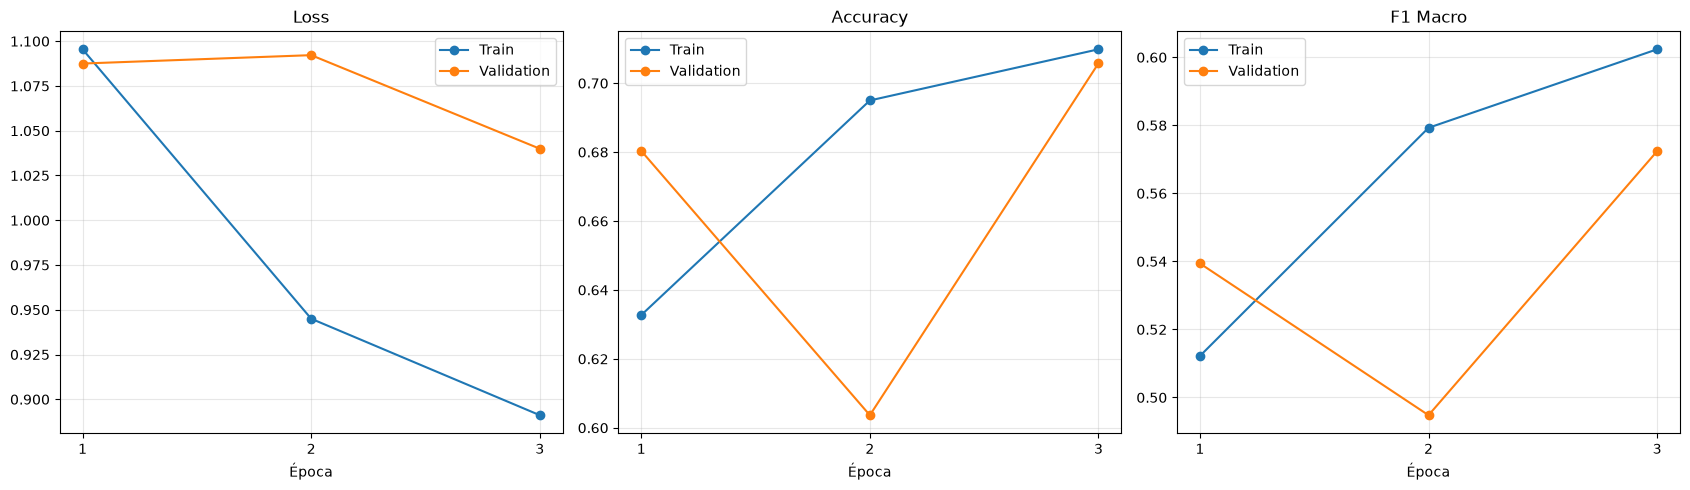

In [24]:
plot_training_history(
    history_fe,
    save_path=(
        REPORT_DIR
        / "feature_extraction_curves.png"
    )
)

In [25]:
configure_trainable_layers(
    model=model,
    model_name=MODEL_NAME,
    mode="partial_finetuning"
)

display(
    count_parameters(model)
)

{'total_parameters': 4208437,
 'trainable_parameters': 2189365,
 'frozen_parameters': 2019072,
 'trainable_percentage': 52.023233328668105}

In [26]:
optimizer_ft = create_optimizer(

    model=model,

    model_name=MODEL_NAME,

    classifier_lr=pipeline_config[
        "partial_finetuning"
    ]["classifier_lr"],

    backbone_lr=pipeline_config[
        "partial_finetuning"
    ]["backbone_lr"],

    weight_decay=pipeline_config[
        "optimizer"
    ]["weight_decay"]

)

scheduler_ft = create_scheduler(
    optimizer=optimizer_ft,
    factor=0.5,
    patience=1,
    min_lr=1e-7
)

for group in optimizer_ft.param_groups:

    print(
        "Grupo:", group["name"],
        "| LR:", group["lr"]
    )

Grupo: classifier | LR: 0.0001
Grupo: backbone | LR: 1e-05


In [27]:
history_ft, summary_ft = fit(

    model=model,

    model_name=MODEL_NAME,

    train_loader=train_loader,

    val_loader=val_loader,

    optimizer=optimizer_ft,

    criterion=criterion,

    device=DEVICE,

    num_classes=NUM_CLASSES,

    epochs=PILOT_FT_EPOCHS,

    checkpoint_dir=(
        CHECKPOINT_DIR / "partial_finetuning"
    ),

    log_dir=(
        LOG_DIR / "partial_finetuning"
    ),

    report_dir=(
        REPORT_DIR / "partial_finetuning"
    ),

    accumulation_steps=ACCUMULATION_STEPS,

    use_amp=USE_AMP,

    scheduler=scheduler_ft,

    patience=3,

    metadata=experiment_metadata

)

Epoch 01/02 | Train Loss: 1.0646 | Val Loss: 1.0629 | Train F1: 0.5038 | Val F1: 0.5136 | Tiempo: 4.20 min
Nuevo mejor checkpoint.
Epoch 02/02 | Train Loss: 0.9244 | Val Loss: 1.0015 | Train F1: 0.5789 | Val F1: 0.5463 | Tiempo: 4.68 min
Nuevo mejor checkpoint.


In [28]:
df_stage_comparison = pd.DataFrame([

    {
        "stage": "feature_extraction",
        **summary_fe
    },

    {
        "stage": "partial_finetuning",
        **summary_ft
    }

])

display(
    df_stage_comparison[
        [
            "stage",
            "best_epoch",
            "best_f1_macro",
            "epochs_completed",
            "total_seconds"
        ]
    ]
)

df_stage_comparison.drop(
    columns=["metadata"]
).to_csv(
    REPORT_DIR / "stage_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

,stage,best_epoch,best_f1_macro,epochs_completed,total_seconds
0,feature_extraction,3,0.572400,3,728.051337
1,partial_finetuning,2,0.546258,2,532.417366


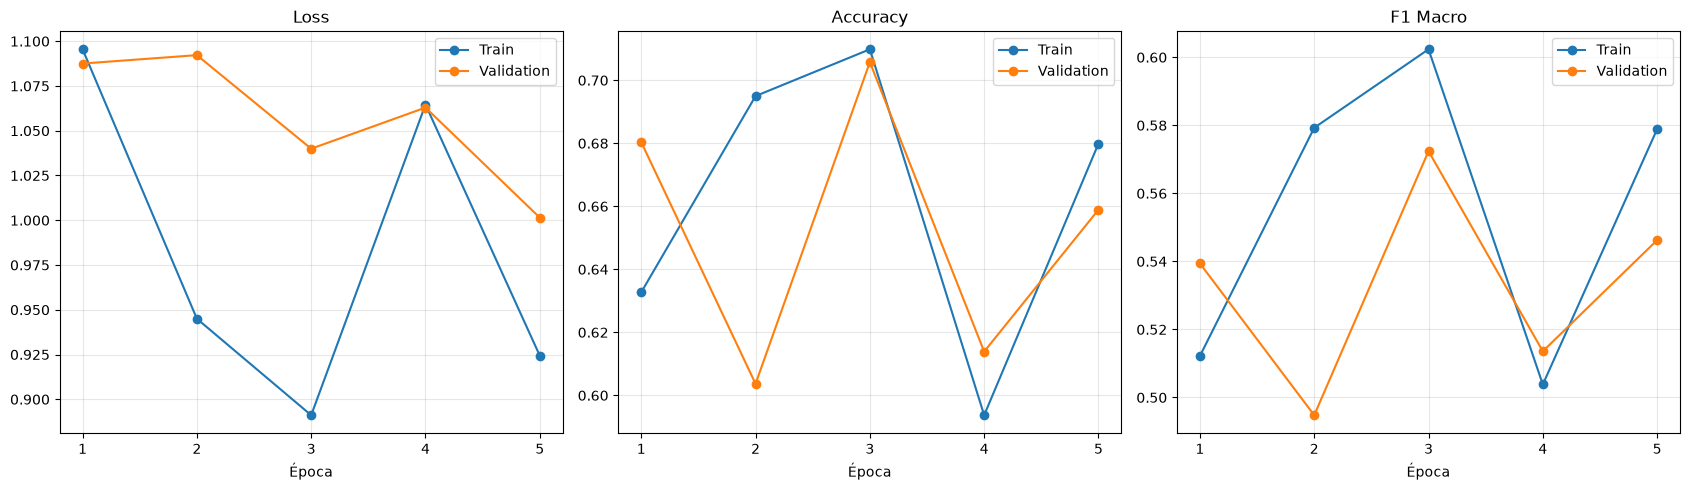

In [29]:
history_fe_plot = history_fe.copy()

history_fe_plot["stage"] = (
    "feature_extraction"
)

history_ft_plot = history_ft.copy()

history_ft_plot["stage"] = (
    "partial_finetuning"
)

history_ft_plot["epoch"] += len(
    history_fe_plot
)

history_combined = pd.concat(
    [
        history_fe_plot,
        history_ft_plot
    ],
    ignore_index=True
)

history_combined.to_csv(
    REPORT_DIR / "combined_history.csv",
    index=False,
    encoding="utf-8-sig"
)

plot_training_history(
    history_combined,
    save_path=(
        REPORT_DIR / "combined_curves.png"
    )
)

In [30]:
if (
    summary_ft["best_f1_macro"]
    > summary_fe["best_f1_macro"]
):

    BEST_STAGE = "partial_finetuning"

else:

    BEST_STAGE = "feature_extraction"


BEST_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / BEST_STAGE
    / "best.pth"
)

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

configure_trainable_layers(
    model=model,
    model_name=MODEL_NAME,
    mode=BEST_STAGE
)

model.eval()

print("Mejor etapa:", BEST_STAGE)

print(
    "Mejor F1 Macro:",
    checkpoint["best_f1_macro"]
)

Mejor etapa: feature_extraction
Mejor F1 Macro: 0.5724000496913045


In [31]:
final_val_metrics, val_predictions = (
    validate_one_epoch(
        model=model,
        dataloader=val_loader,
        criterion=criterion,
        device=DEVICE,
        num_classes=NUM_CLASSES,
        use_amp=USE_AMP,
        return_predictions=True
    )
)

display(
    pd.DataFrame(
        [final_val_metrics]
    )
)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples
0,0.705756,0.593179,0.614729,0.5724,0.72312,0.614729,1.039953,72.589226,6063


In [32]:
detailed_metrics = calculate_detailed_metrics(

    y_true=val_predictions["y_true"],

    y_pred=val_predictions["y_pred"],

    class_mapping=CLASS_MAPPING

)

df_classification_report = pd.DataFrame(
    detailed_metrics["classification_report"]
).transpose()

display(
    df_classification_report.round(4)
)

df_classification_report.to_csv(
    REPORT_DIR / "classification_report.csv",
    encoding="utf-8-sig"
)

,precision,recall,f1-score,support
bacterial_blight,0.3455,0.6753,0.4571,308.0000
brown_streak_disease,0.6042,0.4155,0.4924,621.0000
green_mottle,0.7057,0.4541,0.5527,676.0000
healthy,0.3822,0.7315,0.5021,730.0000
mosaic_disease,0.9282,0.7972,0.8577,3728.0000
accuracy,0.7058,0.7058,0.7058,0.7058
macro avg,0.5932,0.6147,0.5724,6063.0000
weighted avg,0.7749,0.7058,0.7231,6063.0000


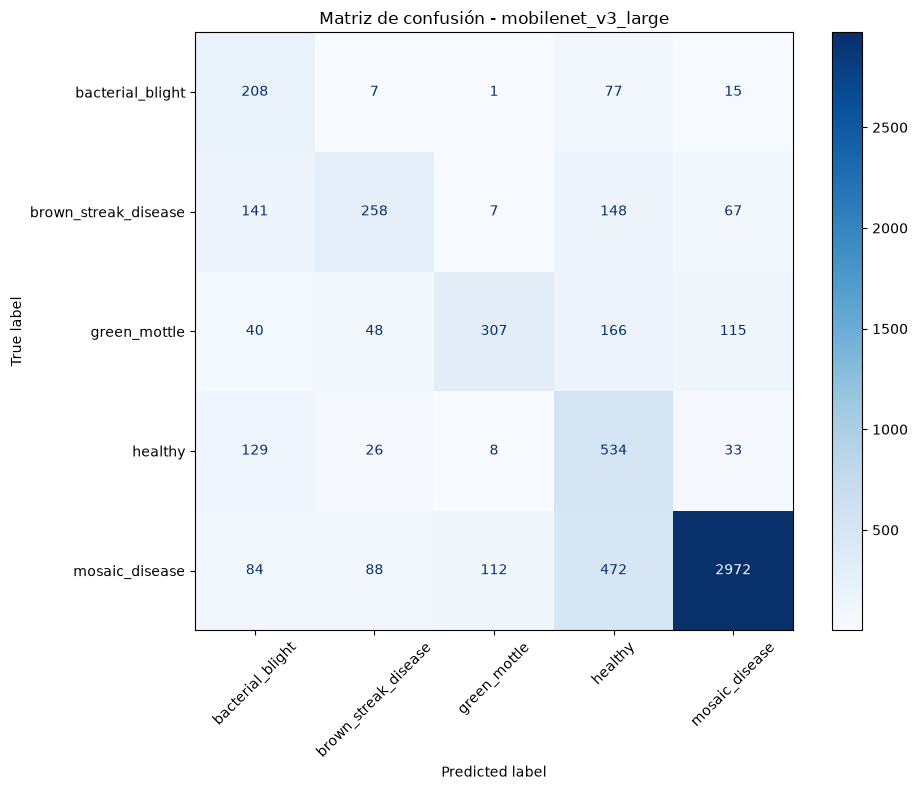

In [33]:
matrix = np.array(
    detailed_metrics["confusion_matrix"]
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

display_matrix = ConfusionMatrixDisplay(

    confusion_matrix=matrix,

    display_labels=(
        detailed_metrics["class_names"]
    )

)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

ax.set_title(
    f"Matriz de confusión - {MODEL_NAME}"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [34]:
df_predictions = df_val[
    ["filepath", "class", "fold"]
].reset_index(drop=True).copy()

df_predictions["y_true"] = (
    val_predictions["y_true"]
)

df_predictions["y_pred"] = (
    val_predictions["y_pred"]
)

probabilities = np.array(
    val_predictions["probabilities"]
)

assert probabilities.shape == (
    len(df_predictions),
    NUM_CLASSES
)

assert np.allclose(
    probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

for class_name, class_id in CLASS_MAPPING.items():

    df_predictions[
        f"prob_{class_name}"
    ] = probabilities[:, class_id]

df_predictions.to_csv(
    REPORT_DIR / "validation_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

display(df_predictions.head())

,filepath,class,fold,y_true,y_pred,prob_bacterial_blight,prob_brown_streak_disease,prob_green_mottle,prob_healthy,prob_mosaic_disease
0,mosaic_disease\1537596204.jpg,mosaic_disease,1,4,4,0.003234,0.005960,0.002251,0.297710,0.690846
1,green_mottle\2484137183.jpg,green_mottle,1,2,2,0.006642,0.033930,0.725449,0.128237,0.105743
2,mosaic_disease\15787336.jpg,mosaic_disease,1,4,4,0.003449,0.008988,0.002032,0.005501,0.980030
3,healthy\3283270801.jpg,healthy,1,3,3,0.405399,0.010199,0.070862,0.512473,0.001068
4,bacterial_blight\272170079.jpg,bacterial_blight,1,0,0,0.798718,0.001669,0.000265,0.198817,0.000532


In [35]:
df_real_performance = pd.DataFrame([

    {
        "architecture": MODEL_NAME,
        "mode": "feature_extraction",
        "batch_size": BATCH_SIZE,
        "mean_train_seconds": (
            history_fe["train_seconds"].mean()
        ),
        "mean_val_seconds": (
            history_fe["val_seconds"].mean()
        ),
        "mean_epoch_minutes": (
            history_fe["epoch_seconds"].mean()
            / 60
        ),
        "images_per_second": (
            history_fe["train_num_samples"].sum()
            / history_fe["train_seconds"].sum()
        )
    },

    {
        "architecture": MODEL_NAME,
        "mode": "partial_finetuning",
        "batch_size": BATCH_SIZE,
        "mean_train_seconds": (
            history_ft["train_seconds"].mean()
        ),
        "mean_val_seconds": (
            history_ft["val_seconds"].mean()
        ),
        "mean_epoch_minutes": (
            history_ft["epoch_seconds"].mean()
            / 60
        ),
        "images_per_second": (
            history_ft["train_num_samples"].sum()
            / history_ft["train_seconds"].sum()
        )
    }

])

display(
    df_real_performance.round(4)
)

df_real_performance.to_csv(
    REPORT_DIR / "real_training_performance.csv",
    index=False,
    encoding="utf-8-sig"
)

,architecture,mode,batch_size,mean_train_seconds,mean_val_seconds,mean_epoch_minutes,images_per_second
0,mobilenet_v3_large,feature_extraction,16,175.1610,67.5201,4.0447,69.2163
1,mobilenet_v3_large,partial_finetuning,16,191.3292,74.8766,4.4368,63.3672


In [36]:
assert len(history_fe) > 0

assert len(history_ft) > 0

assert np.isfinite(
    history_fe["train_loss"]
).all()

assert np.isfinite(
    history_ft["train_loss"]
).all()

assert history_combined[
    "val_f1_macro"
].between(0, 1).all()

assert history_combined[
    "train_accuracy"
].between(0, 1).all()

assert BEST_CHECKPOINT_PATH.exists()

assert PIPELINE_CONFIG_PATH.exists()

assert matrix.shape == (
    NUM_CLASSES,
    NUM_CLASSES
)

assert matrix.sum() == len(
    val_loader.dataset
)

assert len(df_predictions) == len(
    val_loader.dataset
)

assert np.isclose(
    final_val_metrics["f1_macro"],
    checkpoint["best_f1_macro"],
    atol=1e-6
)

print("=" * 60)

print("FASE 2 - PARTE 3 COMPLETADA")

print("=" * 60)

print("Pipeline de entrenamiento: funcional")

print("Weighted CrossEntropyLoss: implementada")

print("Mixed Precision:", USE_AMP)

print("Gradient Accumulation: implementada")

print("AdamW: implementado")

print("Scheduler: implementado")

print("Early Stopping: implementado")

print("Checkpoints: generados")

print("TensorBoard: registros generados")

print("Feature Extraction: verificado")

print("Fine-Tuning parcial: verificado")

print("Mejor etapa:", BEST_STAGE)

print(
    "Mejor F1 Macro:",
    final_val_metrics["f1_macro"]
)

print("Test reservado: no utilizado")

FASE 2 - PARTE 3 COMPLETADA
Pipeline de entrenamiento: funcional
Weighted CrossEntropyLoss: implementada
Mixed Precision: True
Gradient Accumulation: implementada
AdamW: implementado
Scheduler: implementado
Early Stopping: implementado
Checkpoints: generados
TensorBoard: registros generados
Feature Extraction: verificado
Fine-Tuning parcial: verificado
Mejor etapa: feature_extraction
Mejor F1 Macro: 0.5724000496913045
Test reservado: no utilizado


In [37]:
del model

del optimizer

del optimizer_ft

del scheduler

del scheduler_ft

del criterion

del checkpoint

gc.collect()

if DEVICE.type == "cuda":

    torch.cuda.empty_cache()

print("Memoria liberada.")

Memoria liberada.


In [38]:
for stage, history in [
    ("feature_extraction", history_fe),
    ("partial_finetuning", history_ft)
]:

    expected_steps = math.ceil(
        len(train_loader) / ACCUMULATION_STEPS
    )

    df_steps = history[
        ["epoch", "train_optimizer_steps"]
    ].copy()

    df_steps["expected_steps"] = expected_steps

    df_steps["skipped_steps"] = (
        df_steps["expected_steps"]
        - df_steps["train_optimizer_steps"]
    )

    df_steps["skipped_pct"] = (
        df_steps["skipped_steps"]
        / df_steps["expected_steps"]
        * 100
    )

    print("\nModalidad:", stage)

    display(df_steps)


Modalidad: feature_extraction


,epoch,train_optimizer_steps,expected_steps,skipped_steps,skipped_pct
0,1,374,379,5,1.319261
1,2,379,379,0,0.000000
2,3,379,379,0,0.000000



Modalidad: partial_finetuning


,epoch,train_optimizer_steps,expected_steps,skipped_steps,skipped_pct
0,1,371,379,8,2.110818
1,2,379,379,0,0.000000


In [79]:
TRAINING_CONFIG_PATH = (
    CONFIGS_DIR / "training_config.json"
)

with open(
    TRAINING_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:
    training_config = json.load(f)

training_config["training"]["mixed_precision"] = (
    DEVICE.type == "cuda"
)

training_config["training"]["amp"] = {
    "dtype": "float16",
    "init_scale": 1024.0,
    "growth_factor": 2.0,
    "backoff_factor": 0.5,
    "growth_interval": 2000
}

with open(
    TRAINING_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        training_config,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Configuración AMP actualizada.")

Configuración AMP actualizada.


In [80]:
PRECISION_REPORT_PATH = (
    REPORTS_DIR / "amp_precision_benchmark.csv"
)

df_precision_test.to_csv(
    PRECISION_REPORT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Reporte guardado en:")
print(PRECISION_REPORT_PATH)

Reporte guardado en:
C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\reports\amp_precision_benchmark.csv
